### EXperiment No : 06

#### Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics
from sklearn.metrics import ConfusionMatrixDisplay

#### K-Nearest Neighbour Classifier

#### Load The dataset

In [2]:
df=pd.read_csv('Iris.csv')
df.head()

,Sepal length,Sepal width,Petal length,Petal width,Species
0,4.5,2.3,1.3,0.3,setosa
1,5.7,4.4,1.5,0.4,setosa
2,7.9,3.8,6.4,2.0,virginica
3,7.7,3.8,6.7,2.2,virginica
4,7.7,2.6,6.9,2.3,virginica


#### Explore data and Check For Missing Values

In [3]:
print("Shape:", df.shape)
print(df.isnull().sum())
print(df.iloc[:, -1].value_counts())
df.describe()

Shape: (150, 5)
Sepal length    0
Sepal width     0
Petal length    0
Petal width     0
Species         0
dtype: int64
Species
setosa        50
virginica     50
versicolor    50
Name: count, dtype: int64


,Sepal length,Sepal width,Petal length,Petal width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


#### Split into features and target, then split train/test

In [4]:
X = df.iloc[:, :4]
y = df.iloc[:, 4]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (120, 4)  Test: (30, 4)


#### Feature Scaling

In [5]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on train only
X_test_s = scaler.transform(X_test)         # only transform on test

#### KNN using sklearn

In [6]:
knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn.fit(X_train_s, y_train)
y_pred = knn.predict(X_test_s)

print("Sklearn KNN accuracy:", round(metrics.accuracy_score(y_test, y_pred) * 100, 2), "%")


Sklearn KNN accuracy: 96.67 %


#### Evaluate The Model

Confusion Matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



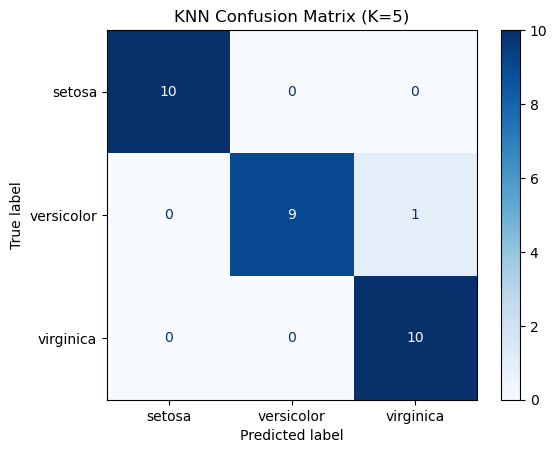

In [7]:
print("Confusion Matrix:\n", metrics.confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", metrics.classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title("KNN Confusion Matrix (K=5)")
plt.show()

#### Find The Best-K

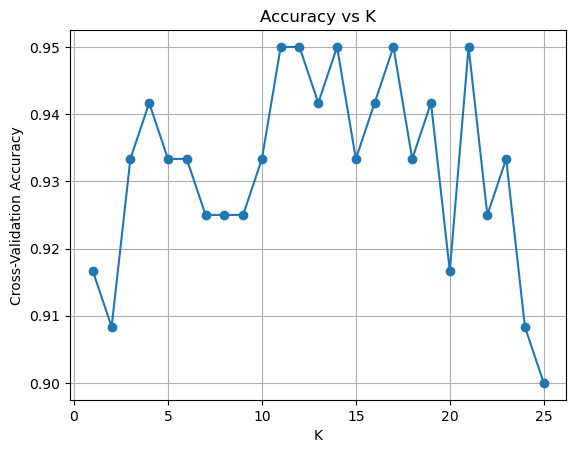

Best K: 11


In [8]:
k_values = range(1, 26)
scores = []

for k in k_values:
    m = KNeighborsClassifier(n_neighbors=k)
    cv_scores = cross_val_score(m, X_train_s, y_train, cv=5)
    scores.append(cv_scores.mean())

plt.plot(k_values, scores, marker='o')
plt.xlabel("K")
plt.ylabel("Cross-Validation Accuracy")
plt.title("Accuracy vs K")
plt.grid(True)
plt.show()

best_k = list(k_values)[int(np.argmax(scores))]
print("Best K:", best_k)

#### Compare Distance metrics and Scaling

In [9]:
for metric in ['euclidean', 'manhattan']:
    m = KNeighborsClassifier(n_neighbors=5, metric=metric).fit(X_train_s, y_train)
    print(metric, "->", round(m.score(X_test_s, y_test) * 100, 2), "%")

raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print("Without scaling ->", round(raw.score(X_test, y_test) * 100, 2), "%")
print("With scaling    ->", round(knn.score(X_test_s, y_test) * 100, 2), "%")

euclidean -> 96.67 %
manhattan -> 93.33 %
Without scaling -> 93.33 %
With scaling    -> 96.67 %


#### Cross-Validation

In [10]:
cv = cross_val_score(KNeighborsClassifier(n_neighbors=5), X_train_s, y_train, cv=5)
print("CV scores:", cv)
print("Mean CV accuracy:", round(cv.mean() * 100, 2), "%")

CV scores: [1.         0.875      0.91666667 0.91666667 0.95833333]
Mean CV accuracy: 93.33 %
